# AO simulation preprocessing

> !!! Batch saving not implemented !!!

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import h5py
import numpy as np
import pandas as pd
from matplotlib.patches import Circle
import os

DELETE_OLD_FILES = False

SMALL_SIZE = 20
MEDIUM_SIZE = 22
BIGGER_SIZE = 25
GPU = True
outputDir = "output_prep/"
inputDir = "dataInputs/"

Parameters = "ao_metadata.txt"

diff_lim_file_name = "diff_lim_"

file_names = ["ao_DM_", "ao_lightfield_", "ao_psf_", "ao_rwfe_", "ao_WFS_"]

metadata = pd.read_csv(inputDir + Parameters, sep="\t", header=None, skiprows=1, index_col=0)
metadaty_keys = metadata.keys()
iterationPerBatch = metadata.loc["batchItSize"][1]
nActWSF = metadata.loc["nActWSF"][1]
edge_act = metadata.loc["edge_act"][1]
act_tot = nActWSF + 2*edge_act
startDelay = metadata.loc["startDelay"][1]
exposureTime = metadata.loc["Exposure time"][1]
nBatch = metadata.loc["nBatch"][1]
batchItSize = metadata.loc["batchItSize"][1]
LastBatchItSize = metadata.loc["LastBatchItSize"][1]

In [2]:
def circle_to_square(positions_1d, Nact1D=11):
    dm_array = np.zeros((Nact1D, Nact1D))
    y, x = np.ogrid[:Nact1D, :Nact1D]
    center = (Nact1D - 1) / 2
    dist_sq = (x - center)**2 + (y - center)**2
    # Get indices of N closest points to center
    sorted_indices = np.argsort(dist_sq.flatten())
    active_indices = sorted_indices[:len(positions_1d)]
    dm_array.flat[active_indices] = positions_1d
    return dm_array

# RWFE

1. Initialized but unused iterations are dropped.

<>:17: SyntaxWarning: invalid escape sequence '\l'
<>:17: SyntaxWarning: invalid escape sequence '\l'
C:\Users\amd\AppData\Local\Temp\ipykernel_14456\1357789416.py:17: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel("RWFE [$\lambda$]", fontsize=MEDIUM_SIZE)


RWFE shape:  (1, 10200)


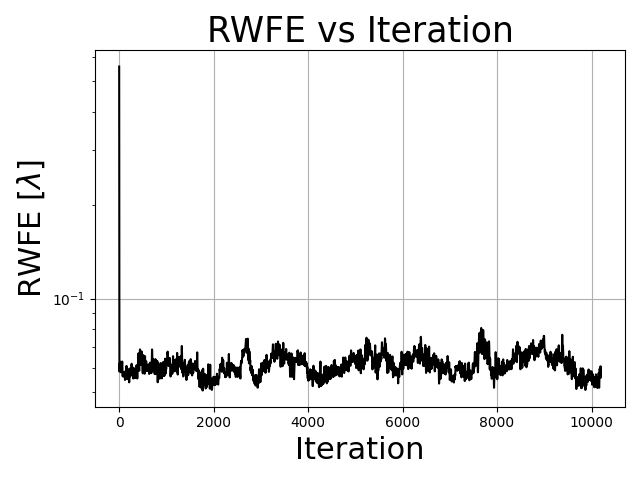

In [3]:
with h5py.File(inputDir+file_names[3]+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    RWFE = temp[key[0]][()][:,:int(LastBatchItSize)]


if os.path.exists(inputDir+file_names[3]+str(1)+".h5"):
    if DELETE_OLD_FILES: os.remove(inputDir+file_names[3]+str(1)+".h5")

    with h5py.File(outputDir+file_names[3]+"prep_"+str(1)+".h5", "w") as f:
        f.create_dataset("RWFE", data=RWFE)

print("RWFE shape: ", RWFE.shape)

plt.close(0)
plt.figure(0)
plt.semilogy(RWFE[0,:],'k')
plt.ylabel("RWFE [$\lambda$]", fontsize=MEDIUM_SIZE)
plt.xlabel("Iteration", fontsize=MEDIUM_SIZE)
plt.title("RWFE vs Iteration", fontsize=BIGGER_SIZE)
plt.grid()
plt.tight_layout()
plt.show()

del RWFE

## DM preprocessing

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.
3. The data is reshaped from 1x97 to 11x11 arrays with zero values where the (11*11-97) don't exist

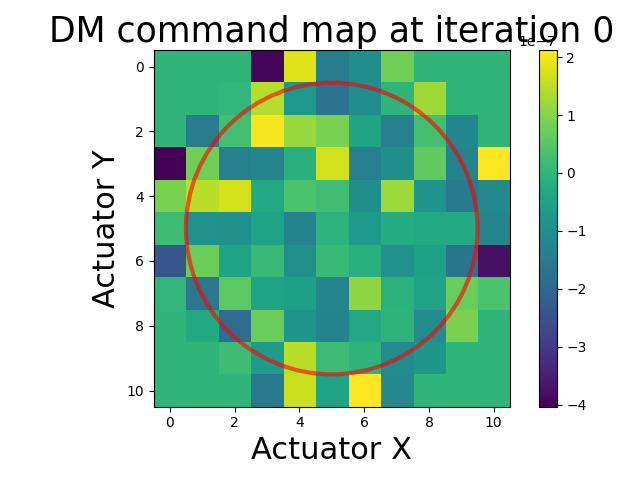

In [4]:
with h5py.File(inputDir+file_names[0]+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    ao_DM = temp[key[0]][()][int(startDelay):,:]
    
DM = np.zeros((int(LastBatchItSize-startDelay), int(act_tot), int(act_tot)))

for i in range(0, int(LastBatchItSize-startDelay)):
    DM[i] = circle_to_square(ao_DM[i], Nact1D=int(act_tot))

if os.path.exists(inputDir+file_names[0]+str(1)+".h5"):
    if DELETE_OLD_FILES: os.remove(inputDir+file_names[0]+str(1)+".h5")

    with h5py.File(outputDir+file_names[0]+"prep_"+str(1)+".h5", "w") as f:
        f.create_dataset("DM commands", data=DM)

plt.close(0)
plt.figure(0)
plt.imshow(DM[0])
circle = Circle((5, 5), 4.5, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.title("DM command map at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()
plt.ylabel("Actuator Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Actuator X", fontsize=MEDIUM_SIZE)
plt.tight_layout()

del ao_DM
del DM

## WFS

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.
3. $\frac{\partial W}{dx}$ and $\frac{\partial W}{dx}$ are separated

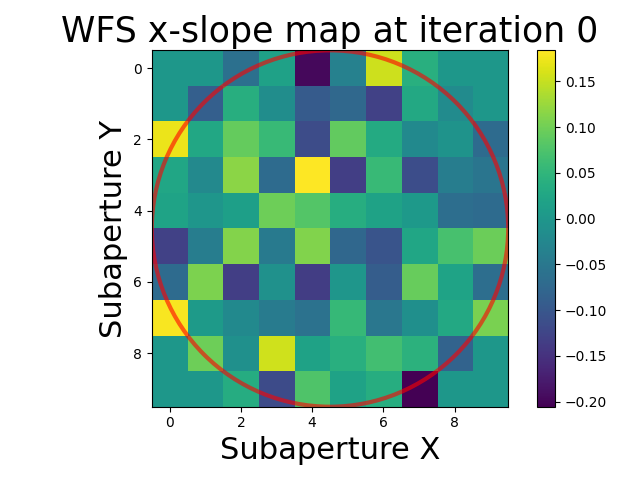

In [21]:
with h5py.File(inputDir+file_names[4]+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    WFSxy = temp[key[0]][()][int(startDelay):,:]

# print(WFSxy.shape[1]//2)

WFSx = np.zeros((int(LastBatchItSize-startDelay), int(act_tot)-1, int(act_tot)-1))
WFSy = np.zeros((int(LastBatchItSize-startDelay), int(act_tot)-1, int(act_tot)-1))

for i in range(0, int(LastBatchItSize-startDelay)):
    WFSx[i] = circle_to_square(WFSxy[i,0:WFSxy.shape[1]//2], Nact1D=int(act_tot)-1)
    WFSy[i] = circle_to_square(WFSxy[i,WFSxy.shape[1]//2:], Nact1D=int(act_tot)-1)

if os.path.exists(inputDir+file_names[4]+str(1)+".h5"):
    if DELETE_OLD_FILES: os.remove(inputDir+file_names[4]+str(1)+".h5")

    with h5py.File(outputDir+file_names[4]+"x_"+"prep_"+str(1)+".h5", "w") as f:
        f.create_dataset("WFS x", data=WFSx)
    with h5py.File(outputDir+file_names[4]+"y_"+"prep_"+str(1)+".h5", "w") as f:
        f.create_dataset("WFS y", data=WFSy)


plt.close(0)
plt.figure(0)
plt.imshow(WFSx[0])
plt.ylabel("Subaperture Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Subaperture X", fontsize=MEDIUM_SIZE)
plt.title("WFS x-slope map at iteration 0", fontsize=BIGGER_SIZE)
circle = Circle((4.5, 4.5), 5, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.colorbar()
plt.tight_layout()
plt.show()

del WFSxy
del WFSx
del WFSy

## Lightfield

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.

(10100, 270, 270)
(10100, 270, 270)


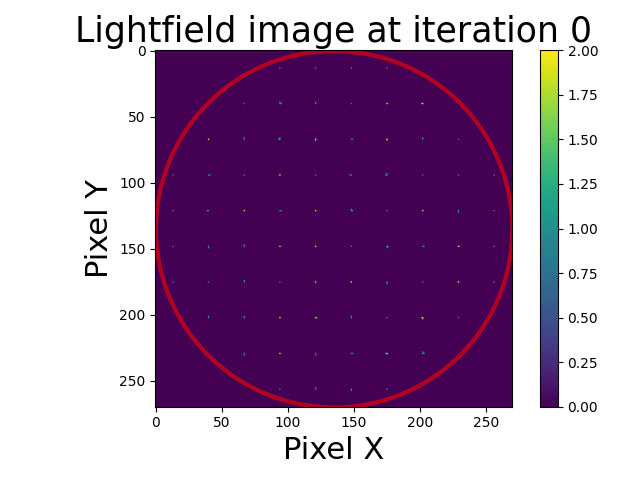

In [22]:
with h5py.File(inputDir+file_names[1]+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    lightfields = temp[key[0]][()][int(startDelay):int(LastBatchItSize),:]

print(lightfields.shape)

if os.path.exists(inputDir+file_names[1]+str(1)+".h5"):
    if DELETE_OLD_FILES: os.remove(inputDir+file_names[1]+str(1)+".h5")

    with h5py.File(outputDir+file_names[1]+"prep_"+str(1)+".h5", "w") as f:
        f.create_dataset("Lightfield", data=lightfields)

plt.close(0)
plt.figure(0)
plt.imshow(lightfields[0])
plt.title("Lightfield image at iteration 0", fontsize=BIGGER_SIZE)
circle = Circle((270/2, 270/2), 270/2, color='red', fill=False, linewidth=3,alpha=0.6)
plt.gca().add_patch(circle)
plt.colorbar()
plt.ylabel("Pixel Y", fontsize=MEDIUM_SIZE)
plt.xlabel("Pixel X", fontsize=MEDIUM_SIZE)
plt.tight_layout()
print(lightfields.shape)
del lightfields

# PSF

1. The first StartDelay values are dropped.
2. Initialized but unused iterations are dropped.

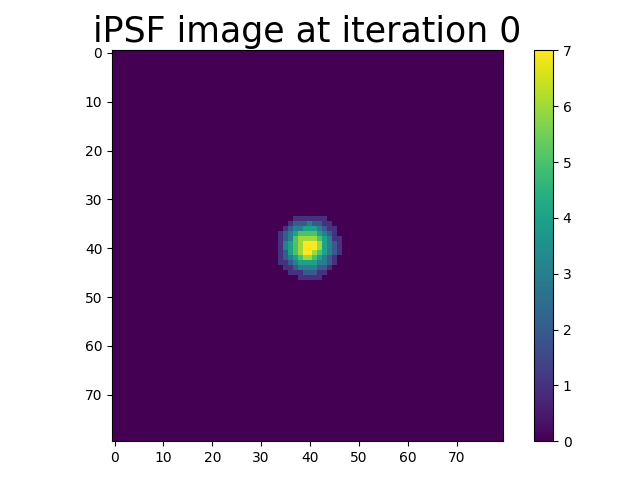

In [24]:
with h5py.File(inputDir+file_names[2]+str(1)+".h5", 'r') as temp:
    key = list(temp.keys())
    iPSFs = temp[key[0]][()][int(startDelay):int(LastBatchItSize),:]


if os.path.exists(inputDir+file_names[2]+str(1)+".h5"):
    if DELETE_OLD_FILES: os.remove(inputDir+file_names[2]+str(1)+".h5")

    with h5py.File(outputDir+file_names[2]+"prep_"+str(1)+".h5", "w") as f:
        f.create_dataset("iPSF", data=iPSFs)

plt.close(0)
plt.figure(0)
plt.imshow(iPSFs[159])
plt.title("iPSF image at iteration 0", fontsize=BIGGER_SIZE)
plt.colorbar()
plt.tight_layout()

del iPSFs